<a href="https://colab.research.google.com/github/mariayicellimon-design/r_hr-employee-attrition-prediction/blob/main/Predicci%C3%B3n_Drivers_Gemini_V1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Predicción de Drivers (Tráfico, Conversión, Ticket Promedio) — versión corregida

**Qué se corrigió respecto a la versión anterior**

1. **Split temporal real.** Antes se ordenaba por `Unidad de Negocio` y luego `TimeSeriesSplit` cortaba por *posición de fila*, es decir por bloques de unidad: el train contenía fechas iguales y posteriores a las del test, y el fold 5 evaluaba unidades nunca vistas. Ahora los folds se definen por **fecha** (`train` < `test` para todas las unidades) y hay un `assert` que lo verifica.
2. **Lags/rollings sobre calendario completo.** Se construyen sobre una grilla fecha × unidad *antes* de cualquier recorte, y solo se descartan filas por NaN en los lags (no `dropna()` global).
3. **Simulación recursiva (cascada) correcta.** Arranca en el primer día del test de cada fold, se siembra con historia real previa, **oculta los valores reales del horizonte** y simula `HORIZONTE` días. El error se reporta **por horizonte** y contra un baseline ingenuo.
4. **Se separan dos evaluaciones con nombre claro:** *1 día adelante* (usa lags reales, "teacher forcing") y *multi-paso recursivo* (usa sus propias predicciones).
5. **Métricas comparables entre unidades** (WAPE) y baselines (`lag_1`, `lag_7`), porque el MAE y R² agrupados quedan dominados por eCommerce.
6. **Auditorías automáticas** de split, de la construcción de lags y de que el horizonte recursivo no ve datos reales.

> **Supuesto a validar:** las variables exógenas del mismo día (`Dias sin atencion`, `Dias con campaña`, `Descuento %`, calendario) se usan como **conocidas de antemano**. Si `Descuento %` es un valor *realizado* (no planificado), ponga `USAR_DESCUENTO = False`.

### 1. Carga de Datos, Preprocesamiento e Imputación de Anomalías
Limpiamos el dataset de valores negativos en Tráfico y Ticket Promedio, corregimos los outliers de conversión (> 0.8) y re-construimos la grilla completa fecha × unidad de negocio.

In [32]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from google.colab import files
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor

# ---------------- Configuración Global ----------------
FILE_PATH = '/content/drive/MyDrive/DBs/Drivers Históricos MC.xlsx'
SHEET     = 'sheet1'
DATE, UNIT = 'Calendar Date', 'Unidad de Negocio'
TARGETS   = ['Trafico', 'Conversion', 'Ticket Promedio']
USAR_DESCUENTO = True

# Carga de datos
df = pd.read_excel(FILE_PATH, sheet_name=SHEET)
df[DATE] = pd.to_datetime(df[DATE])
assert not df.duplicated([DATE, UNIT]).any(), "Hay filas duplicadas (fecha, unidad)"

# 1. Tratamiento de valores negativos en Tráfico y Ticket Promedio
df['Trafico'] = df['Trafico'].clip(lower=0)
df['Ticket Promedio'] = df['Ticket Promedio'].clip(lower=0)

# 2. Tratamiento de nulos generales
df[TARGETS] = df[TARGETS].fillna(0)
df['Is_Weekend'] = df['Day Of Week'].isin([6, 7]).astype(int)

# 3. Corrección de Outliers de Conversión (> 0.8)
df['Year_Month'] = df[DATE].dt.to_period('M')
promedios_mensuales = df[df['Conversion'] <= 0.8].groupby(['Unidad de Negocio', 'Year_Month'])['Conversion'].mean().reset_index()
promedios_mensuales.rename(columns={'Conversion': 'Conversion_Promedio'}, inplace=True)
df = df.merge(promedios_mensuales, on=['Unidad de Negocio', 'Year_Month'], how='left')

condicion_reemplazo = df['Conversion'] > 0.8
df.loc[condicion_reemplazo, 'Conversion'] = df.loc[condicion_reemplazo, 'Conversion_Promedio']

promedio_historico = df[df['Conversion'] <= 0.8].groupby('Unidad de Negocio')['Conversion'].mean()
df['Conversion'] = df.apply(
    lambda row: promedio_historico[row['Unidad de Negocio']] if row['Conversion'] > 0.8 or pd.isna(row['Conversion']) else row['Conversion'],
    axis=1
)
df.drop(columns=['Year_Month', 'Conversion_Promedio'], inplace=True, errors='ignore')

# 4. Creación de la grilla de tiempo/unidades completa
units     = sorted(df[UNIT].unique())
all_dates = pd.date_range(df[DATE].min(), df[DATE].max(), freq='D')
grid  = pd.MultiIndex.from_product([all_dates, units], names=[DATE, UNIT])
panel = df.set_index([DATE, UNIT]).reindex(grid)
panel['existe'] = panel['Trafico'].notna()
panel = panel.reset_index().sort_values([UNIT, DATE]).reset_index(drop=True)

print(f"Dataset cargado y depurado de anomalías. Unidades: {len(units)} | Rango: {all_dates[0].date()} a {all_dates[-1].date()}")

Dataset cargado y depurado de anomalías. Unidades: 13 | Rango: 2024-01-01 a 2026-10-15


### 2. Generación de Features Históricas (Lags y Medias Móviles)

In [33]:
EXOG = ['Year', 'Month Number', 'Day Of Month', 'Day Of Week', 'Dias sin atencion', 'Dias con campaña', 'Is_Weekend']
if USAR_DESCUENTO:
    EXOG.append('Descuento %')

LAGS, ROLLS = [1, 2, 7], [3, 7]
LAG_FEATS = []
for c in TARGETS:
    g = panel.groupby(UNIT)[c]
    for k in LAGS:
        panel[f'{c}_lag_{k}'] = g.shift(k)
        LAG_FEATS.append(f'{c}_lag_{k}')
    for w in ROLLS:
        panel[f'{c}_roll_mean_{w}'] = panel.groupby(UNIT)[c].transform(lambda s: s.shift(1).rolling(w).mean())
        LAG_FEATS.append(f'{c}_roll_mean_{w}')

UNIT_COLS = [f'{UNIT}_{u}' for u in units]
for u, col in zip(units, UNIT_COLS):
    panel[col] = (panel[UNIT] == u).astype(float)

FEATURE_COLS = EXOG + LAG_FEATS + UNIT_COLS

# Filtramos solo registros donde el lag histórico y exógenas están completos para entrenar
valid = panel['existe'] & panel[LAG_FEATS].notna().all(axis=1) & panel[EXOG].notna().all(axis=1)
data = panel[valid].sort_values([DATE, UNIT]).reset_index(drop=True)

X = data[FEATURE_COLS].astype(float)
Y = data[TARGETS]
print(f"Dimensiones de modelado final: X={X.shape}, Y={Y.shape}")

Dimensiones de modelado final: X=(12922, 36), Y=(12922, 3)


### 3. Split Temporal, Entrenamiento y Simulación Recursiva en Cascada con Reglas de Negocio

In [34]:
def _mat(col):
    return panel.pivot(index=DATE, columns=UNIT, values=col).reindex(index=all_dates, columns=units).to_numpy(float)

REAL  = {c: _mat(c) for c in TARGETS}
EXOGM = {c: _mat(c) for c in EXOG}
EXIST = panel.pivot(index=DATE, columns=UNIT, values='existe').reindex(index=all_dates, columns=units)
EXIST = EXIST.astype(float).fillna(0).astype(bool).to_numpy()
EYE   = np.eye(len(units))
DIDX  = {d: i for i, d in enumerate(all_dates)}

def features_step_safe(A, i):
    """Calcula de forma segura los lags en cascada rellenando nulos con 0"""
    f = {c: EXOGM[c][i] for c in EXOG}
    for c in TARGETS:
        a = A[c]
        f[f'{c}_lag_1'] = np.nan_to_num(a[i-1], nan=0.0)
        f[f'{c}_lag_2'] = np.nan_to_num(a[i-2], nan=0.0)
        f[f'{c}_lag_7'] = np.nan_to_num(a[i-7], nan=0.0)
        f[f'{c}_roll_mean_3'] = np.nan_to_num(a[i-3:i].mean(axis=0), nan=0.0)
        f[f'{c}_roll_mean_7'] = np.nan_to_num(a[i-7:i].mean(axis=0), nan=0.0)
    for j, col in enumerate(UNIT_COLS):
        f[col] = EYE[:, j]
    F = pd.DataFrame(f)[FEATURE_COLS]
    ok = EXIST[i]
    return F, ok

def simular_recursivo_con_reglas(model, cut, H):
    i0 = DIDX[cut]
    i1 = min(i0 + H, len(all_dates))

    A = {c: REAL[c].copy() for c in TARGETS}
    for c in TARGETS:
        A[c][i0:] = np.nan

    idx_o_suc, idx_o_term = units.index('Sucursal Oeste'), units.index('Terminal 1 - Oeste')
    idx_n_suc, idx_n_term = units.index('Sucursal Norte'), units.index('Terminal 1 - Norte')
    idx_u_suc, idx_u_term = units.index('Sucursal Uyuni'), units.index('Terminal 1 - Uyuni')
    idx_corp = units.index('Ventas Corporativas')

    for i in range(i0, i1):
        F, ok = features_step_safe(A, i)
        if ok.any():
            P = model.predict(F.loc[ok, FEATURE_COLS])
            for k, c in enumerate(TARGETS):
                A[c][i, ok] = P[:, k]

            # Forzar valores no negativos para predicciones simuladas
            for c in TARGETS:
                A[c][i, ok] = np.clip(A[c][i, ok], 0, None)

            # Regla de Negocio A: Sincronización de Tráfico entre Sucursales y Terminales
            if EXIST[i, idx_o_term] and EXIST[i, idx_o_suc]:
                A['Trafico'][i, idx_o_term] = A['Trafico'][i, idx_o_suc]
            if EXIST[i, idx_n_term] and EXIST[i, idx_n_suc]:
                A['Trafico'][i, idx_n_term] = A['Trafico'][i, idx_n_suc]
            if EXIST[i, idx_u_term] and EXIST[i, idx_u_suc]:
                A['Trafico'][i, idx_u_term] = A['Trafico'][i, idx_u_suc]

    # Regla de Negocio B: Tráfico constante mensual para Ventas Corporativas
    fechas_simuladas = all_dates[i0:i1]
    meses_unicos = sorted(list(set(f.to_period('M') for f in fechas_simuladas)))
    for mes in meses_unicos:
        indices_mes = [idx for idx, f in enumerate(fechas_simuladas) if f.to_period('M') == mes]
        indices_reales = [i0 + idx for idx in indices_mes]
        valores_trafico = [A['Trafico'][idx, idx_corp] for idx in indices_reales if EXIST[idx, idx_corp] and not np.isnan(A['Trafico'][idx, idx_corp])]
        if valores_trafico:
            promedio_mes = np.mean(valores_trafico)
            for idx in indices_reales:
                if EXIST[idx, idx_corp]:
                    A['Trafico'][idx, idx_corp] = promedio_mes

    return A, i0, i1

# --- Entrenamiento con Split Temporal <= 2026-06-30 ---
LIMITE_TRAIN = pd.Timestamp('2026-06-30')
FECHA_INICIO = pd.Timestamp('2026-07-01')
FECHA_FIN    = pd.Timestamp('2026-10-15')
H_especifico = (FECHA_FIN - FECHA_INICIO).days + 1

tr_final = (data[DATE] <= LIMITE_TRAIN).to_numpy()
print(f"Entrenando modelo final con datos hasta el {LIMITE_TRAIN.date()}...")
model_final = MultiOutputRegressor(RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1))
model_final.fit(X[tr_final], Y[tr_final])

# Simulación en cascada
A_final, i0_f, i1_f = simular_recursivo_con_reglas(model_final, FECHA_INICIO, H_especifico)
print("[OK] Simulación de Cascada completada.")

Entrenando modelo final con datos hasta el 2026-06-30...
[OK] Simulación de Cascada completada.


### 4. Estructuración y Exportación de Resultados

In [35]:
fechas_horizonte_final = all_dates[i0_f:i1_f]

filas_predicciones_final = []
for idx_fecha, fecha in enumerate(fechas_horizonte_final):
    i_real = i0_f + idx_fecha
    for idx_unidad, unidad in enumerate(units):
        if EXIST[i_real, idx_unidad]:
            registro = {
                'Fecha': fecha.strftime('%Y-%m-%d'),
                'Unidad de Negocio': unidad
            }
            for target in TARGETS:
                registro[f'{target}_Pred_Cascada'] = A_final[target][i_real, idx_unidad]
            filas_predicciones_final.append(registro)

df_predicciones_final = pd.DataFrame(filas_predicciones_final)

# Exportar a CSV con delimitador ';' y formato de decimal ','
nombre_archivo_final = 'predicciones_cascada_final.csv'
df_predicciones_final.to_csv(nombre_archivo_final, sep=';', decimal=',', index=False, encoding='utf-8-sig')

print(f"Archivo final '{nombre_archivo_final}' generado exitosamente.")
print(f"Total registros exportados: {len(df_predicciones_final)}.")
display(df_predicciones_final.head(10))

# Descarga directa del archivo
files.download(nombre_archivo_final)

Archivo final 'predicciones_cascada_final.csv' generado exitosamente.
Total registros exportados: 1391.


,Fecha,Unidad de Negocio,Trafico_Pred_Cascada,Conversion_Pred_Cascada,Ticket Promedio_Pred_Cascada
0,2026-07-01,Call Center,756.39,0.006418,1031.396355
1,2026-07-01,Sucursal Megacenter,560.01,0.247027,604.779569
2,2026-07-01,Sucursal Norte,688.16,0.322543,546.992398
3,2026-07-01,Sucursal Oeste,860.11,0.324918,598.258273
4,2026-07-01,Sucursal Sucre,30.68,0.488579,493.600710
5,2026-07-01,Sucursal Sur,359.97,0.267817,378.102488
6,2026-07-01,Sucursal Tarija,54.05,0.413851,455.125969
7,2026-07-01,Sucursal Uyuni,427.65,0.343473,498.205008
8,2026-07-01,Terminal 1 - Norte,688.16,0.010559,492.204910
9,2026-07-01,Terminal 1 - Oeste,860.11,0.011604,558.792164


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [36]:
import pandas as pd
import numpy as np
from sklearn.metrics import r2_score, mean_absolute_error

# Obtener el dataframe real en el horizonte de predicción para la comparación
real_horizonte = []
for idx_fecha, fecha in enumerate(fechas_horizonte_final):
    i_real = i0_f + idx_fecha
    for idx_unidad, unidad in enumerate(units):
        if EXIST[i_real, idx_unidad]:
            registro = {
                'Fecha': fecha.strftime('%Y-%m-%d'),
                'Unidad de Negocio': unidad
            }
            for target in TARGETS:
                registro[f'{target}_Real'] = REAL[target][i_real, idx_unidad]
            real_horizonte.append(registro)

df_real_horizonte = pd.DataFrame(real_horizonte)

# Unimos predicción y real
df_comparacion = pd.merge(df_predicciones_final, df_real_horizonte, on=['Fecha', 'Unidad de Negocio'])

# Cálculo de métricas por unidad
resultados_metricas = []
for unidad in units:
    df_sub = df_comparacion[df_comparacion['Unidad de Negocio'] == unidad]
    if len(df_sub) < 2:
        continue

    metricas_unidad = {'Unidad de Negocio': unidad}
    for target in TARGETS:
        y_real = df_sub[f'{target}_Real'].to_numpy()
        y_pred = df_sub[f'{target}_Pred_Cascada'].to_numpy()

        # Evitar fallos de R2 si no hay varianza en el real
        if np.std(y_real) == 0:
            r2 = 0.0
        else:
            r2 = r2_score(y_real, y_pred)

        mae = mean_absolute_error(y_real, y_pred)
        sum_real = np.sum(np.abs(y_real))
        wape = np.sum(np.abs(y_real - y_pred)) / sum_real if sum_real > 0 else 0.0

        metricas_unidad[f'{target}_R2'] = r2
        metricas_unidad[f'{target}_MAE'] = mae
        metricas_unidad[f'{target}_WAPE'] = wape

    resultados_metricas.append(metricas_unidad)

df_metricas = pd.DataFrame(resultados_metricas)
print("=== MÉTRICAS DE EVALUACIÓN EN EL HORIZONTE DE TEST (CASCADA) ===")
display(df_metricas.round(4))

=== MÉTRICAS DE EVALUACIÓN EN EL HORIZONTE DE TEST (CASCADA) ===


,Unidad de Negocio,Trafico_R2,Trafico_MAE,Trafico_WAPE,Conversion_R2,Conversion_MAE,Conversion_WAPE,Ticket Promedio_R2,Ticket Promedio_MAE,Ticket Promedio_WAPE
0,Call Center,-0.4901,222.0346,0.3791,-4.1595,0.0071,2.1450,-0.0092,624.9105,0.9866
1,Sucursal Megacenter,0.3395,464.0678,0.5141,-0.2914,0.0557,0.2576,0.0062,183.3104,0.3150
2,Sucursal Norte,0.4036,275.0608,0.2354,0.0160,0.0431,0.1378,0.0794,73.7411,0.1319
3,Sucursal Oeste,-0.8205,395.7667,0.3843,-0.8616,0.0677,0.1810,-0.1082,86.6265,0.1321
4,Sucursal Sucre,0.1932,17.0121,0.4876,0.7777,0.0734,0.1717,0.1592,188.6417,0.4453
5,Sucursal Sur,-8.3774,703.8100,1.2124,-1.2693,0.0909,0.4125,-1.6992,164.1293,0.4240
6,Sucursal Tarija,0.1273,30.8999,0.4837,0.6143,0.0889,0.2382,-0.1637,164.6287,0.5079
7,Sucursal Uyuni,-54.8481,1450.9081,2.4764,-0.1085,0.0658,0.1800,-0.1317,87.9901,0.1603
8,Terminal 1 - Norte,0.4036,275.0608,0.2354,-0.1323,0.0039,0.3368,-0.3215,130.9899,0.3235
9,Terminal 1 - Oeste,-0.8205,395.7667,0.3843,-0.2082,0.0039,0.2927,0.0006,153.0183,0.3186


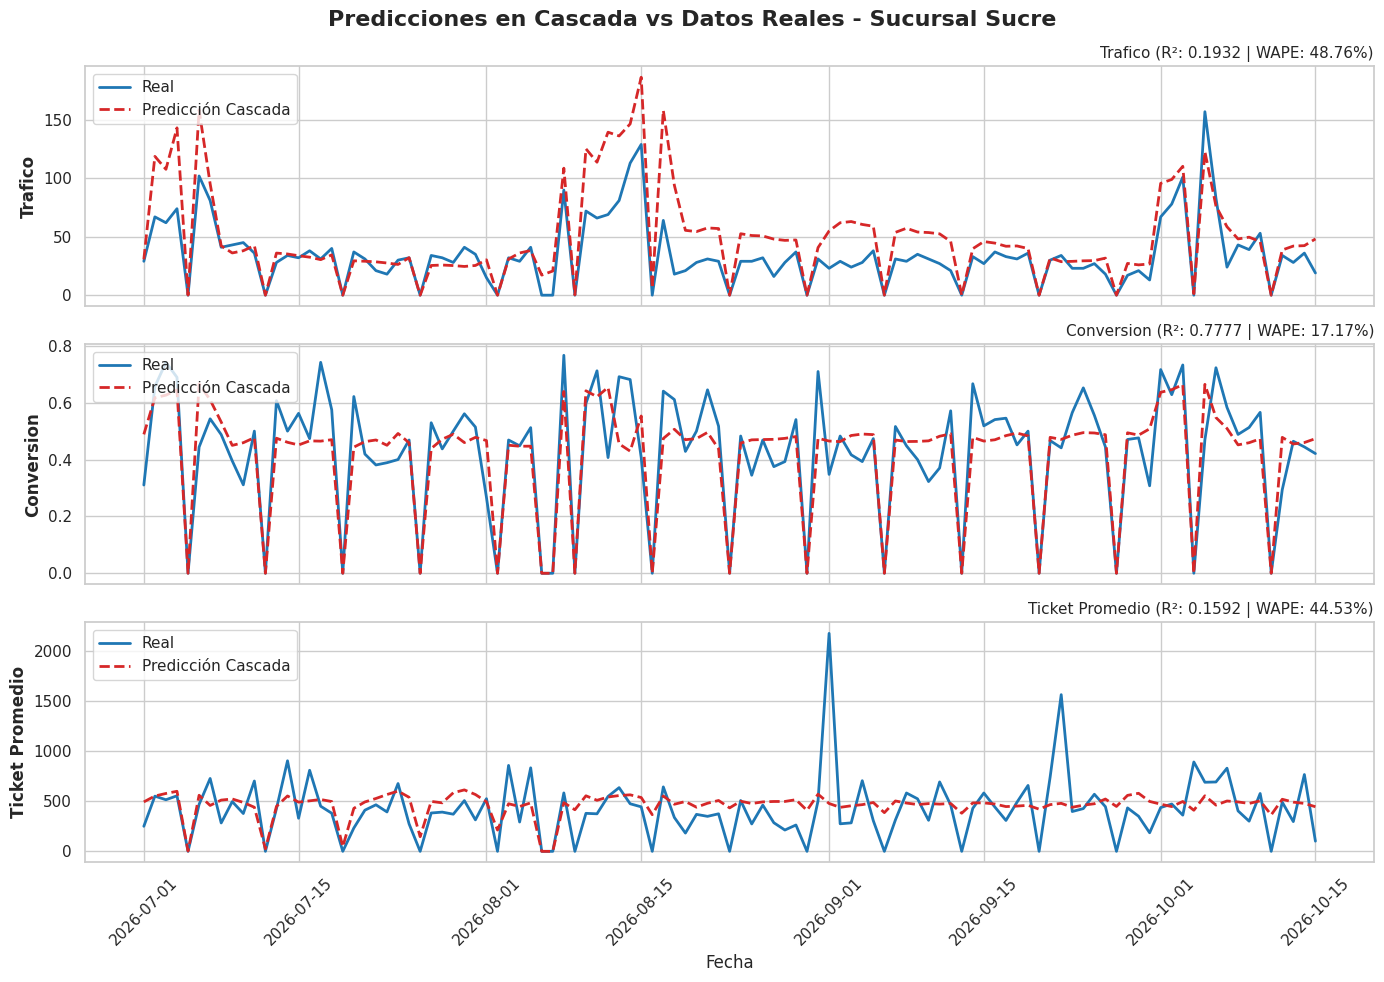

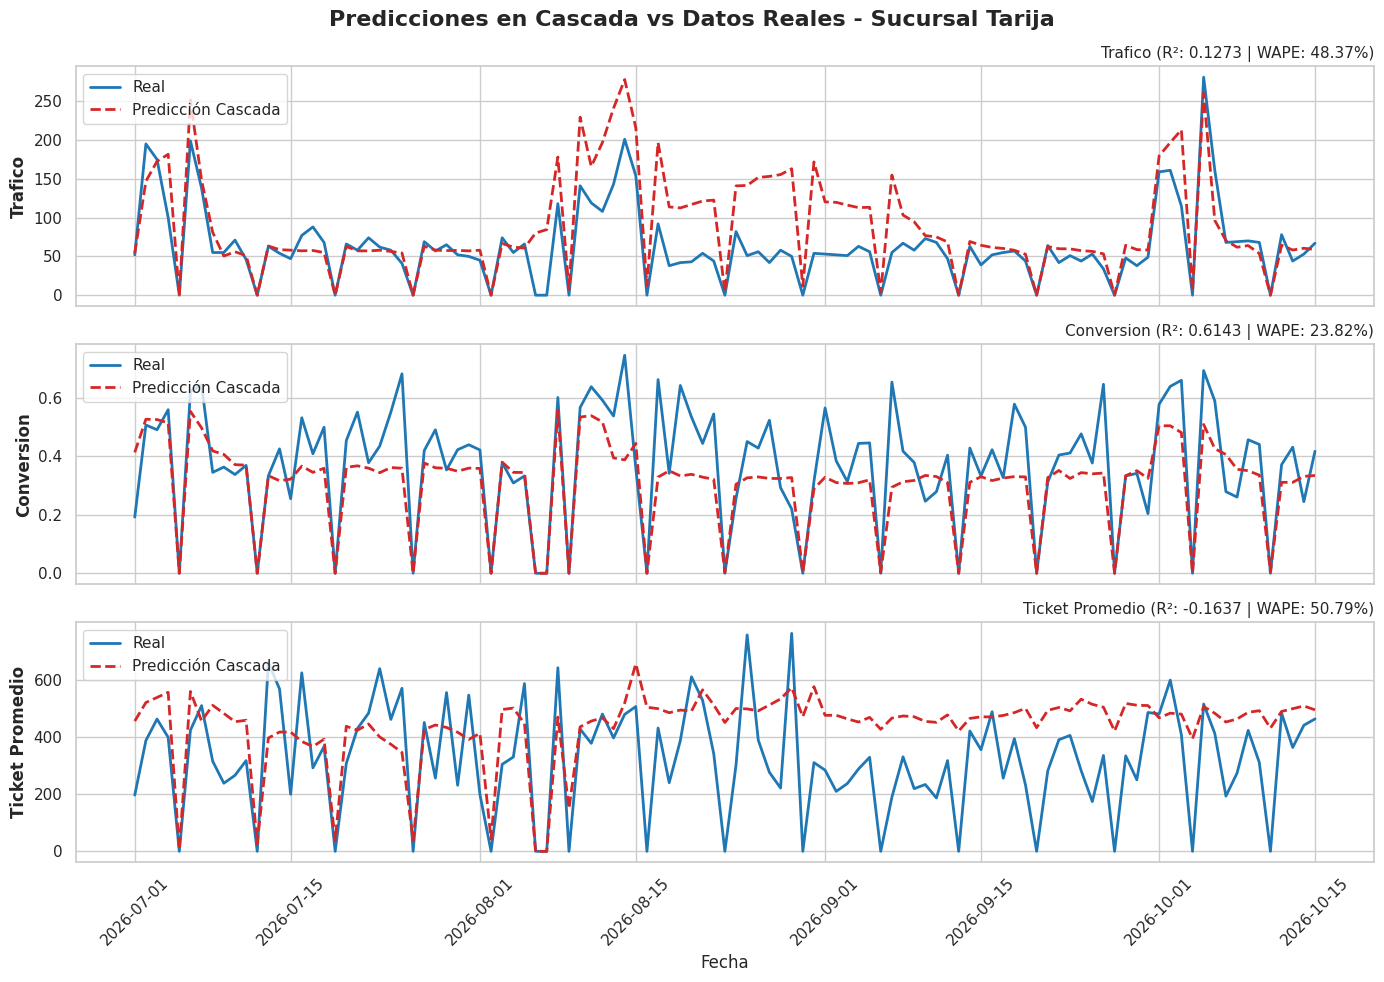

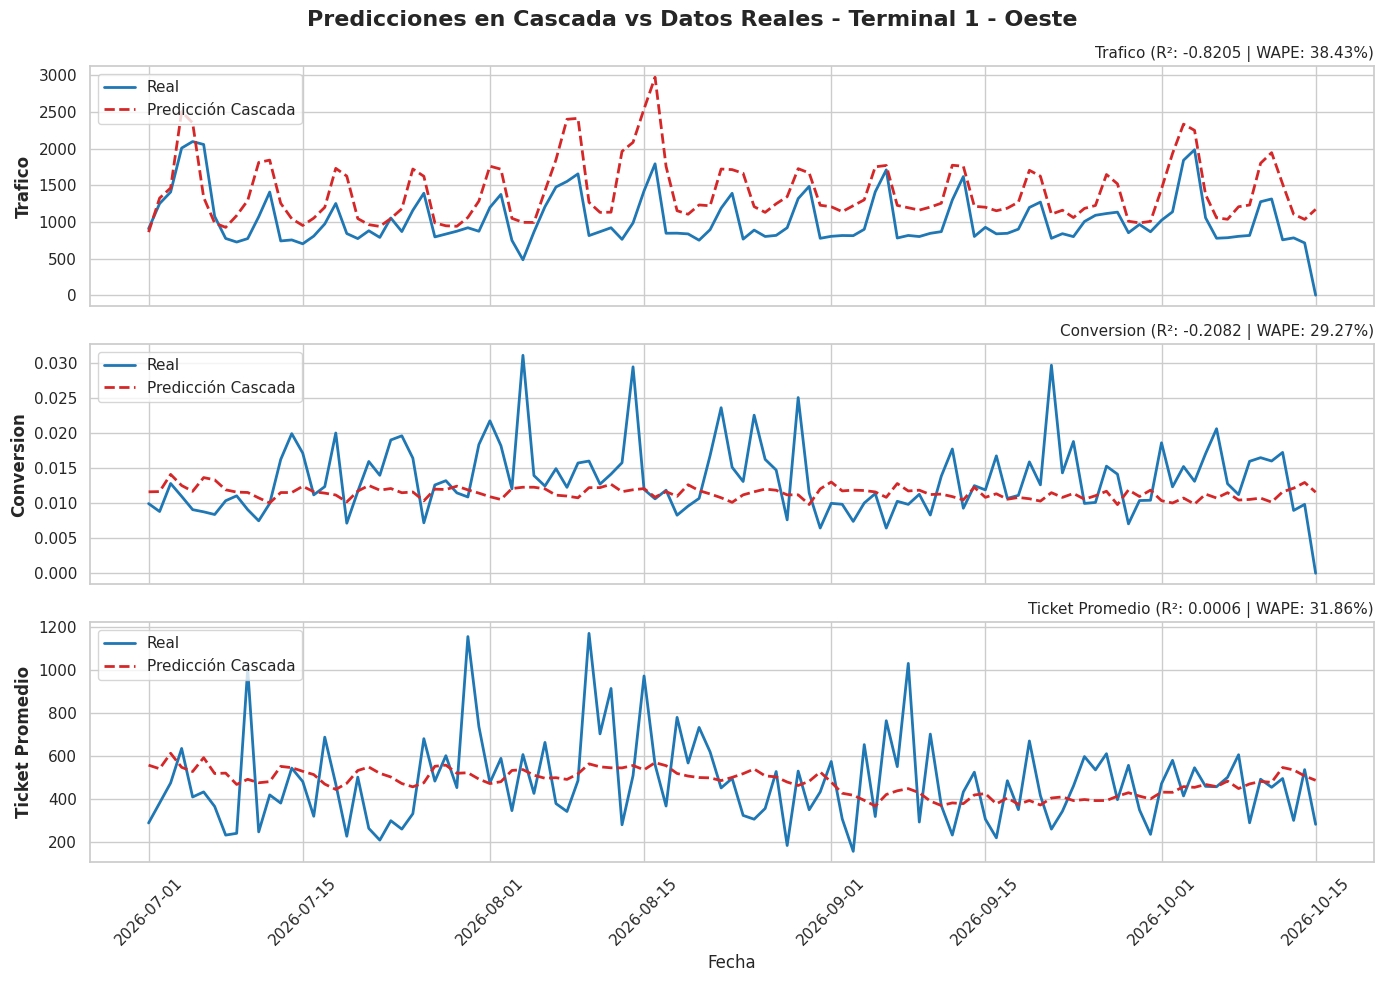

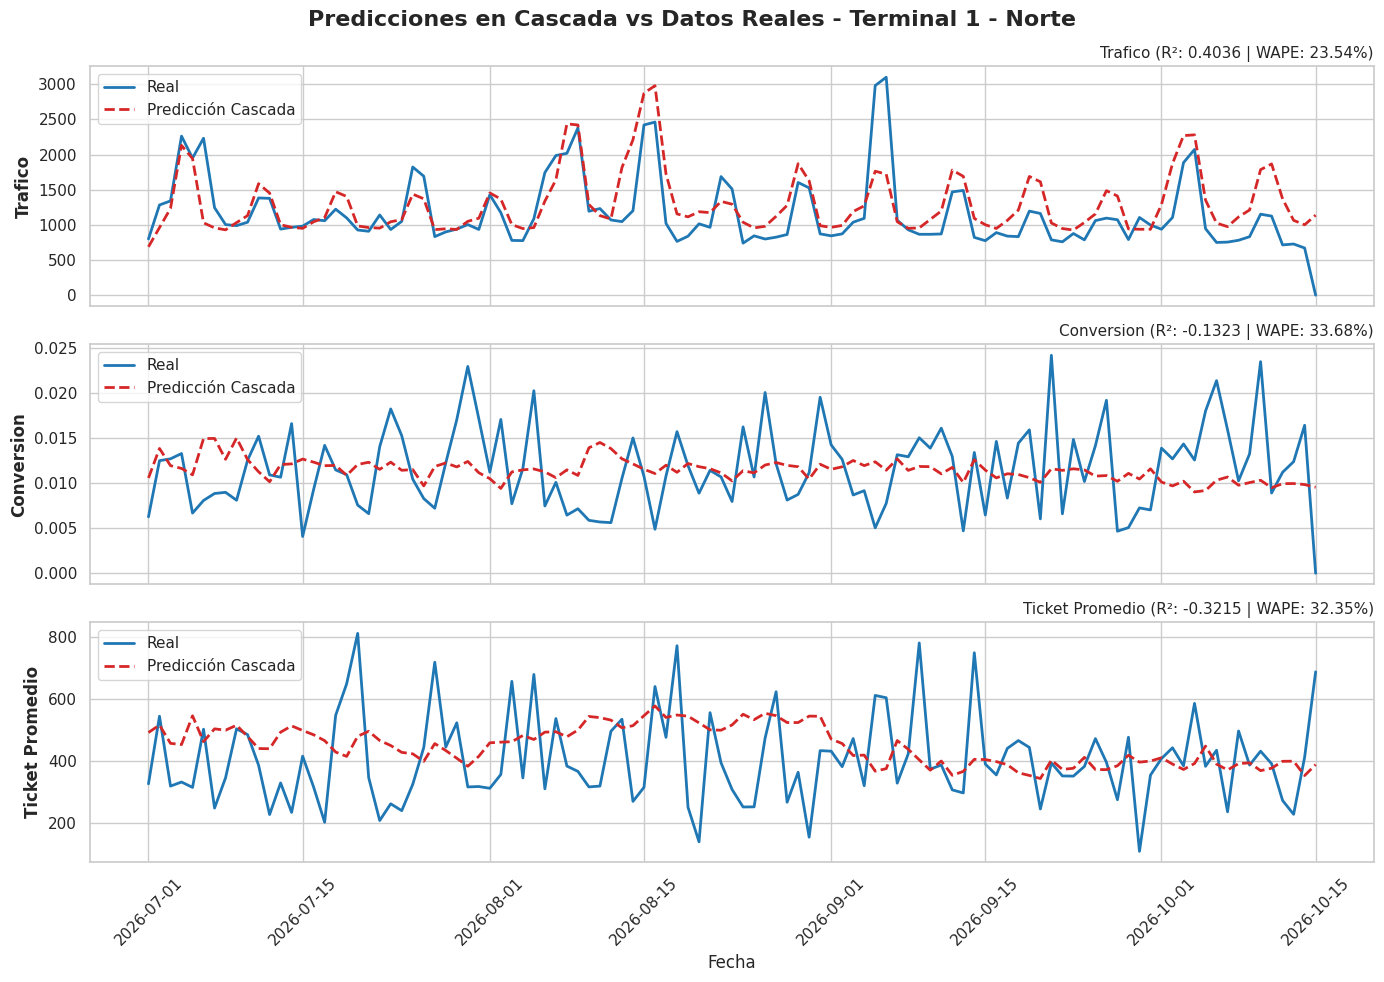

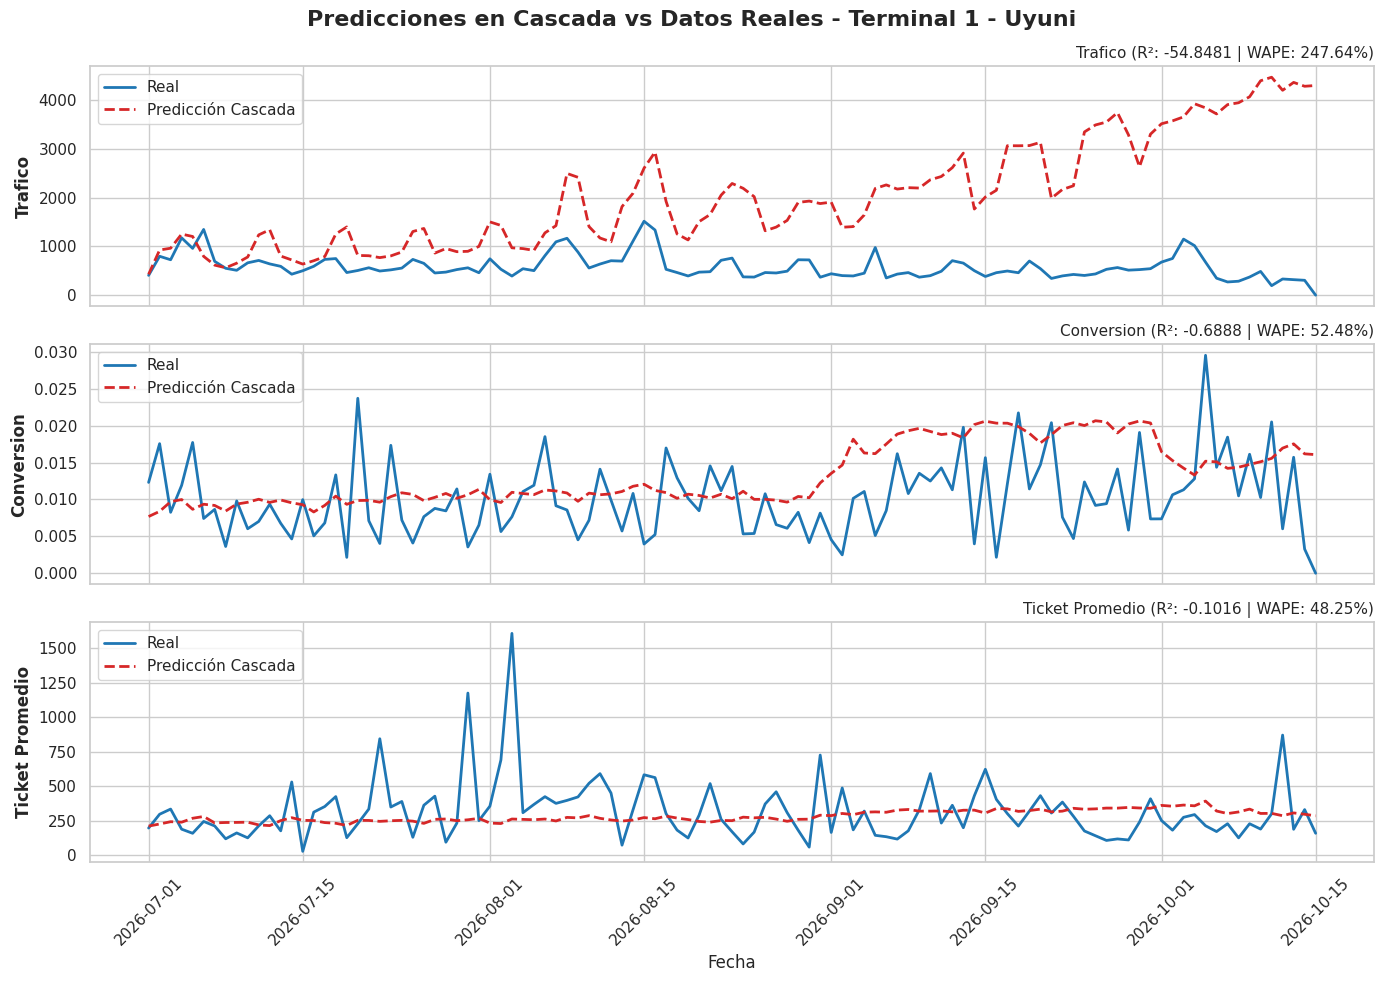

In [40]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Graficaremos las unidades más relevantes para mantener la legibilidad, o puedes iterar sobre todas
unidades_a_graficar = ['Sucursal Sucre', 'Sucursal Tarija', 'Terminal 1 - Oeste', 'Terminal 1 - Norte', 'Terminal 1 - Uyuni']

for unidad in unidades_a_graficar:
    if unidad not in units:
        continue

    df_sub = df_comparacion[df_comparacion['Unidad de Negocio'] == unidad].copy()
    df_sub['Fecha'] = pd.to_datetime(df_sub['Fecha'])
    df_sub = df_sub.sort_values('Fecha')

    fig, axes = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
    fig.suptitle(f"Predicciones en Cascada vs Datos Reales - {unidad}", fontsize=16, fontweight='bold')

    for i, target in enumerate(TARGETS):
        ax = axes[i]
        ax.plot(df_sub['Fecha'], df_sub[f'{target}_Real'], label='Real', color='#1f77b4', linewidth=2)
        ax.plot(df_sub['Fecha'], df_sub[f'{target}_Pred_Cascada'], label='Predicción Cascada', color='#d62728', linestyle='--', linewidth=2)

        ax.set_ylabel(target, fontweight='bold')
        ax.legend(loc='upper left')

        # Mostrar R2 y WAPE local en el título de cada subplot
        r2_val = df_metricas.loc[df_metricas['Unidad de Negocio'] == unidad, f'{target}_R2'].values[0]
        wape_val = df_metricas.loc[df_metricas['Unidad de Negocio'] == unidad, f'{target}_WAPE'].values[0]
        ax.set_title(f"{target} (R²: {r2_val:.4f} | WAPE: {wape_val:.2%})", fontsize=11, loc='right')

    plt.xlabel("Fecha")
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

In [41]:
import numpy as np
import pandas as pd
from sklearn.metrics import r2_score, mean_absolute_error

# 1. Calcular la venta (Trafico * Conversion * Ticket Promedio)
df_comparacion['Venta_Real'] = df_comparacion['Trafico_Real'] * df_comparacion['Conversion_Real'] * df_comparacion['Ticket Promedio_Real']
df_comparacion['Venta_Pred_Cascada'] = df_comparacion['Trafico_Pred_Cascada'] * df_comparacion['Conversion_Pred_Cascada'] * df_comparacion['Ticket Promedio_Pred_Cascada']

# 2. Calcular métricas específicas de Venta por Unidad de Negocio
resultados_venta = []
for unidad in units:
    df_sub = df_comparacion[df_comparacion['Unidad de Negocio'] == unidad]
    if len(df_sub) < 2:
        continue

    y_real = df_sub['Venta_Real'].to_numpy()
    y_pred = df_sub['Venta_Pred_Cascada'].to_numpy()

    if np.std(y_real) == 0:
        r2 = 0.0
    else:
        r2 = r2_score(y_real, y_pred)

    mae = mean_absolute_error(y_real, y_pred)
    sum_real = np.sum(np.abs(y_real))
    wape = np.sum(np.abs(y_real - y_pred)) / sum_real if sum_real > 0 else 0.0

    resultados_venta.append({
        'Unidad de Negocio': unidad,
        'Venta_R2': r2,
        'Venta_MAE': mae,
        'Venta_WAPE': wape
    })

df_metricas_venta = pd.DataFrame(resultados_venta)
print("=== MÉTRICAS DE EVALUACIÓN PARA LA VARIABLE: VENTA (DÓLARES/MONEDA) ===")
display(df_metricas_venta.round(4))

=== MÉTRICAS DE EVALUACIÓN PARA LA VARIABLE: VENTA (DÓLARES/MONEDA) ===


,Unidad de Negocio,Venta_R2,Venta_MAE,Venta_WAPE
0,Call Center,-1.7507,4317.3808,2.0823
1,Sucursal Megacenter,-0.6399,87759.7310,0.8370
2,Sucursal Norte,0.0948,64140.1649,0.3141
3,Sucursal Oeste,0.3858,57674.4974,0.2258
4,Sucursal Sucre,0.1319,5937.7525,0.6257
5,Sucursal Sur,-26.3903,159435.3182,2.9694
6,Sucursal Tarija,0.5792,7399.8124,0.5732
7,Sucursal Uyuni,-19.2147,279407.7107,2.2677
8,Terminal 1 - Norte,-0.6414,2889.2162,0.5510
9,Terminal 1 - Oeste,0.1565,2703.0995,0.4085


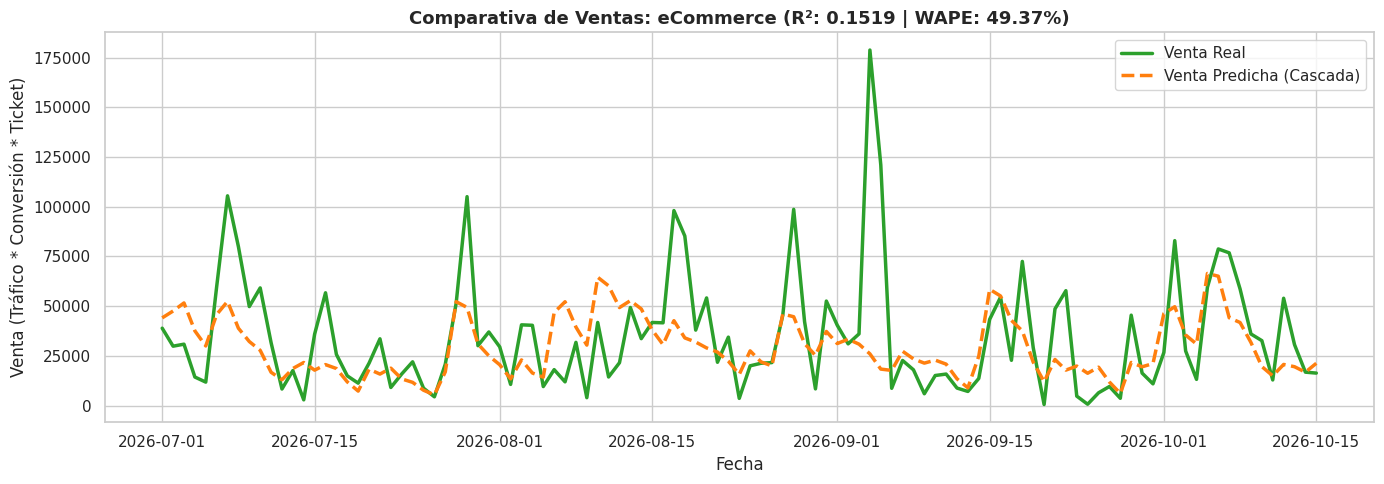

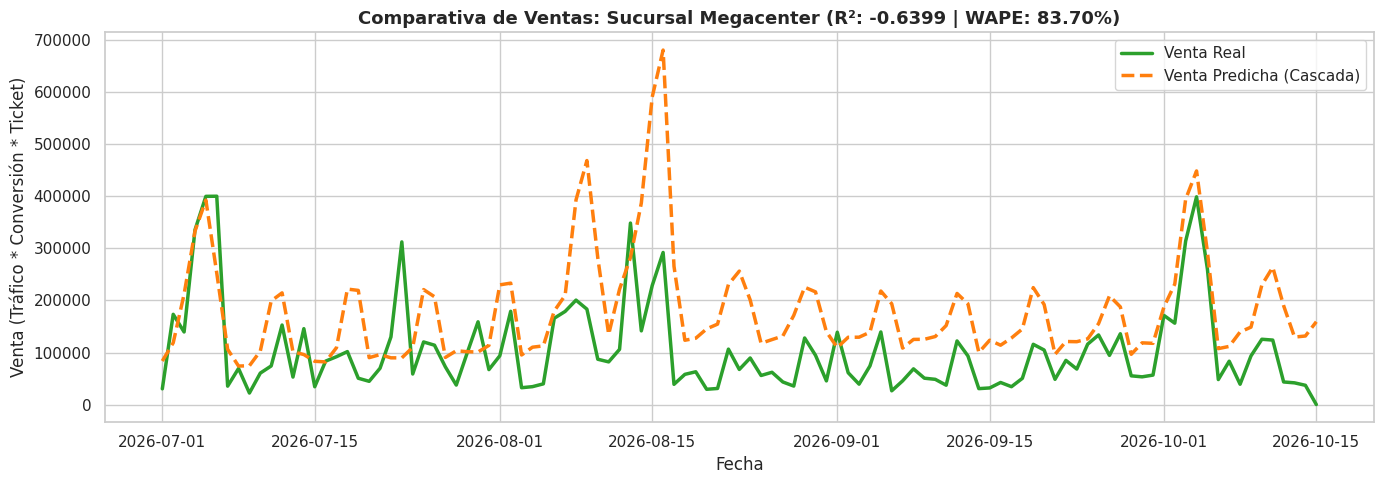

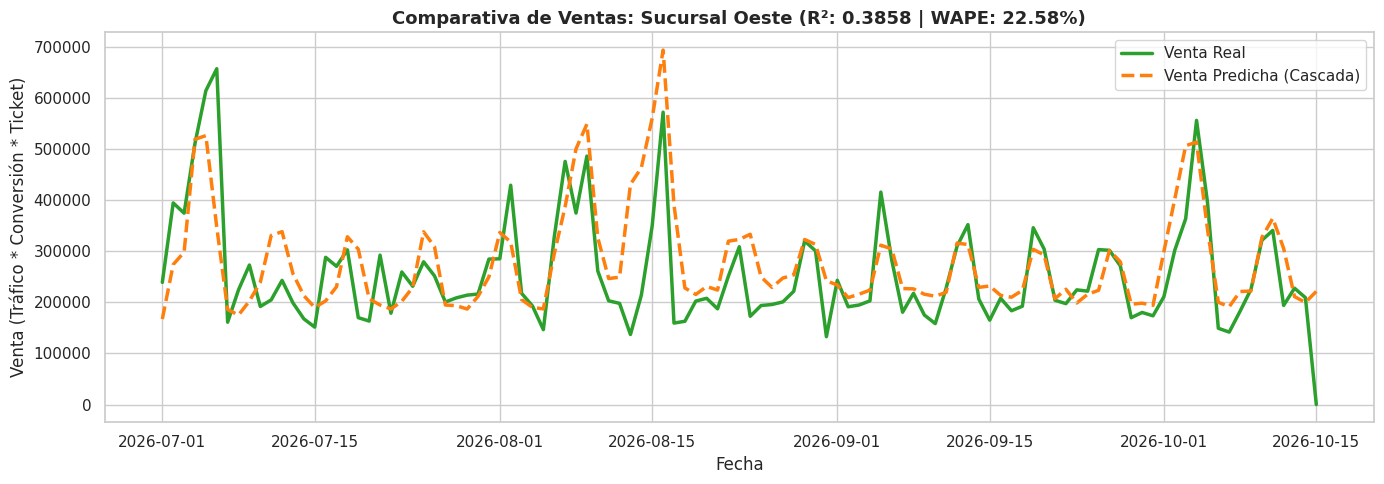

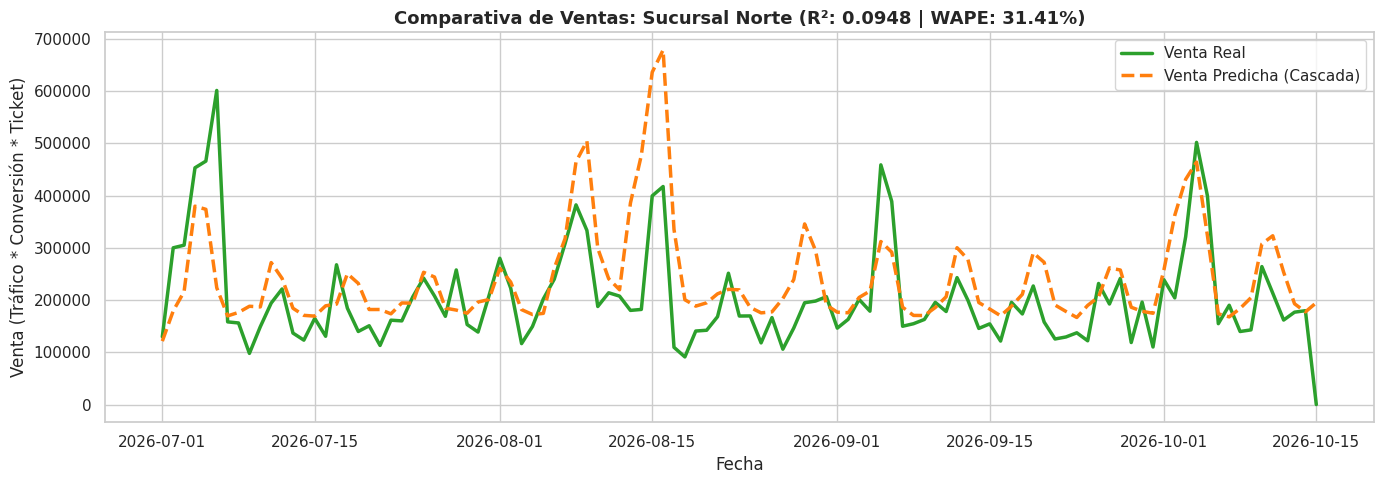

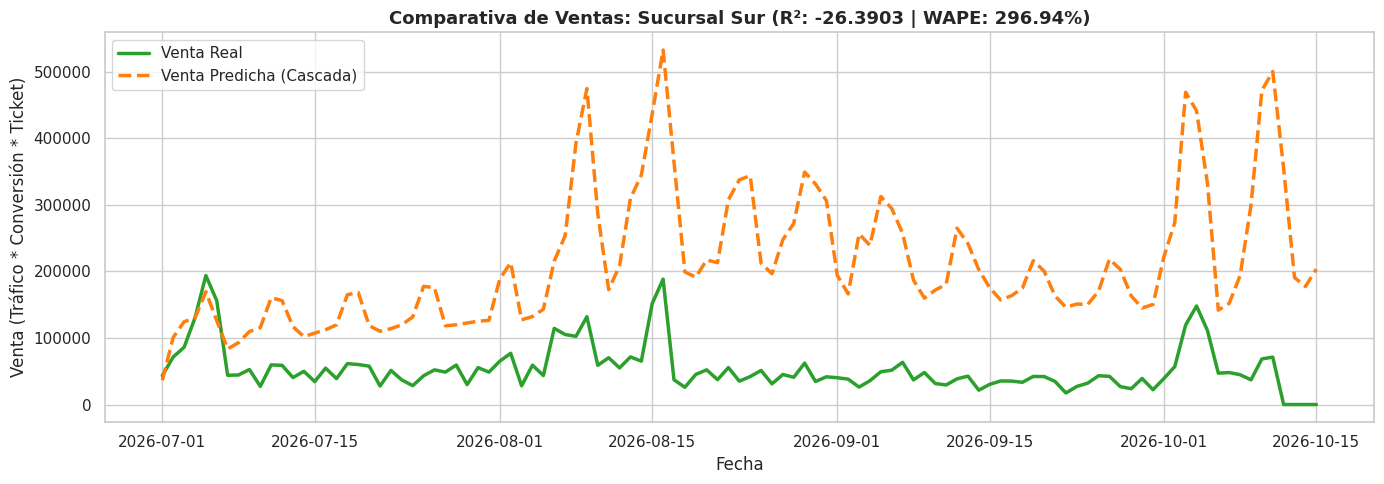

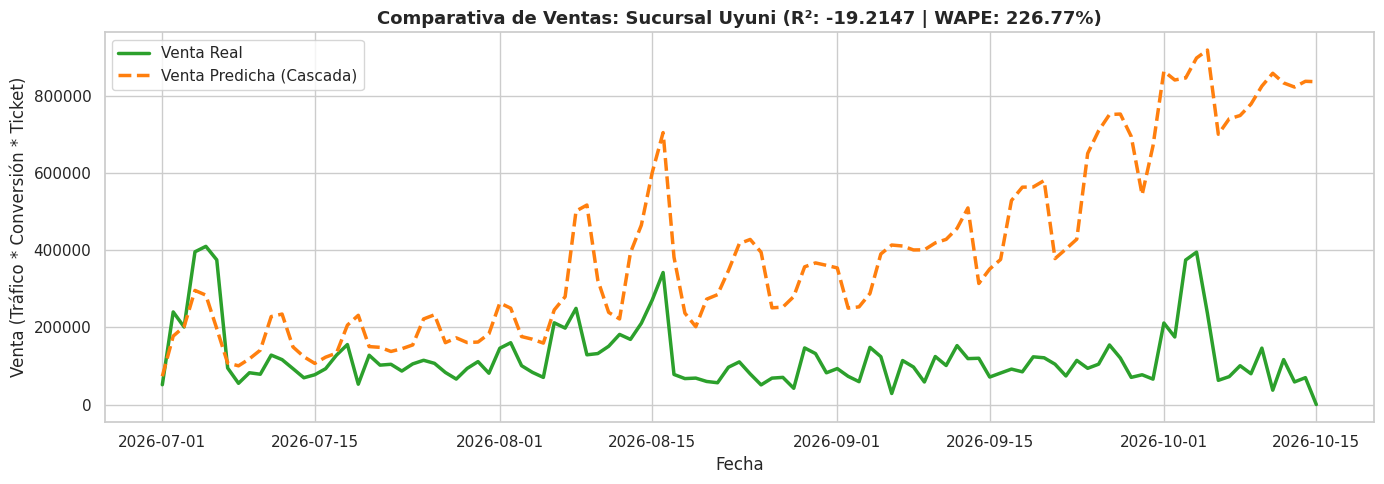

In [42]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Graficamos las unidades de negocio más representativas para la venta final
unidades_venta_grafico = ['eCommerce', 'Sucursal Megacenter', 'Sucursal Oeste', 'Sucursal Norte', 'Sucursal Sur', 'Sucursal Uyuni']

for unidad in unidades_venta_grafico:
    if unidad not in units:
        continue

    df_sub = df_comparacion[df_comparacion['Unidad de Negocio'] == unidad].copy()
    df_sub['Fecha'] = pd.to_datetime(df_sub['Fecha'])
    df_sub = df_sub.sort_values('Fecha')

    plt.figure(figsize=(14, 5))
    plt.plot(df_sub['Fecha'], df_sub['Venta_Real'], label='Venta Real', color='#2ca02c', linewidth=2.5)
    plt.plot(df_sub['Fecha'], df_sub['Venta_Pred_Cascada'], label='Venta Predicha (Cascada)', color='#ff7f0e', linestyle='--', linewidth=2.5)

    r2_val = df_metricas_venta.loc[df_metricas_venta['Unidad de Negocio'] == unidad, 'Venta_R2'].values[0]
    wape_val = df_metricas_venta.loc[df_metricas_venta['Unidad de Negocio'] == unidad, 'Venta_WAPE'].values[0]

    plt.title(f"Comparativa de Ventas: {unidad} (R²: {r2_val:.4f} | WAPE: {wape_val:.2%})", fontsize=13, fontweight='bold')
    plt.xlabel("Fecha")
    plt.ylabel("Venta (Tráfico * Conversión * Ticket)")
    plt.legend()
    plt.tight_layout()
    plt.show()

In [43]:
# 1. Agrupar a nivel diario sumando la venta de todas las unidades de negocio
df_venta_diaria = df_comparacion.groupby('Fecha')[['Venta_Real', 'Venta_Pred_Cascada']].sum().reset_index()
df_venta_diaria['Fecha'] = pd.to_datetime(df_venta_diaria['Fecha'])
df_venta_diaria = df_venta_diaria.sort_values('Fecha')

# 2. Calcular errores y métricas globales para la venta consolidada
y_real_total = df_venta_diaria['Venta_Real'].to_numpy()
y_pred_total = df_venta_diaria['Venta_Pred_Cascada'].to_numpy()

r2_total = r2_score(y_real_total, y_pred_total)
mae_total = mean_absolute_error(y_real_total, y_pred_total)
sum_real_total = np.sum(np.abs(y_real_total))
wape_total = np.sum(np.abs(y_real_total - y_pred_total)) / sum_real_total if sum_real_total > 0 else 0.0

print("=== MÉTRICAS DE EVALUACIÓN GLOBAL (VENTA CONSOLIDADA DIARIA) ===")
print(f"R² Global: {r2_total:.4f}")
print(f"MAE Global: {mae_total:.2f}")
print(f"WAPE Global: {wape_total:.2%}")

=== MÉTRICAS DE EVALUACIÓN GLOBAL (VENTA CONSOLIDADA DIARIA) ===
R² Global: -2.8836
MAE Global: 641375.08
WAPE Global: 76.42%


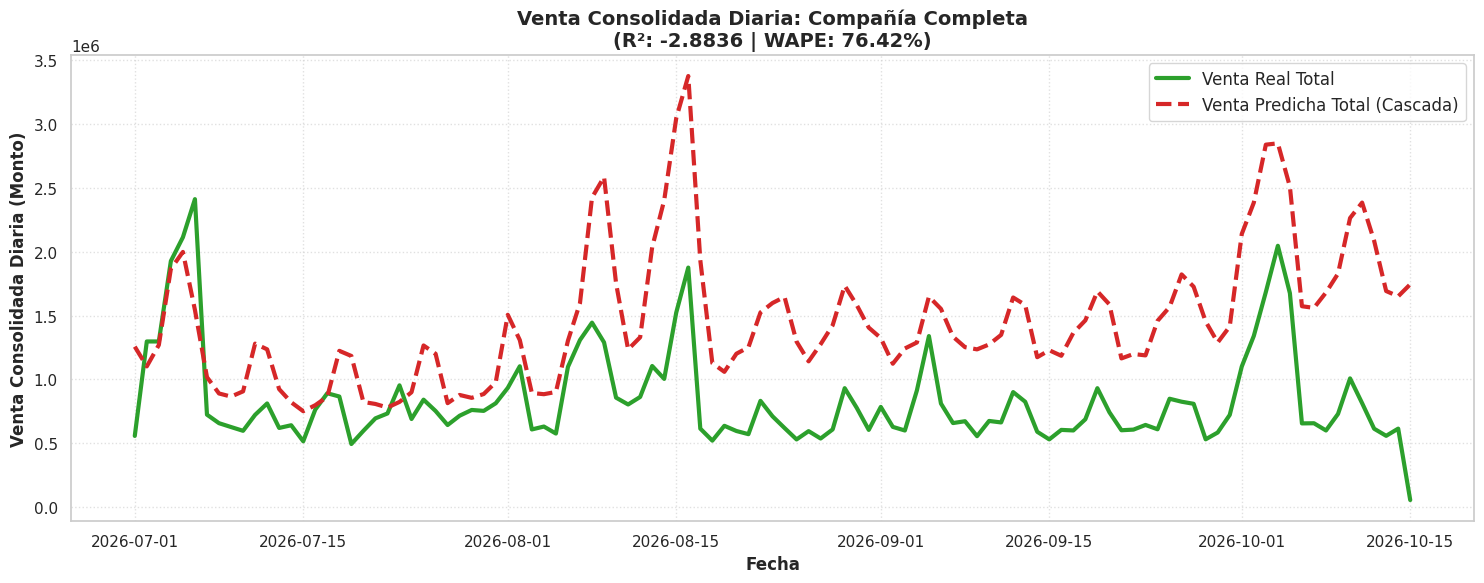

In [44]:
# 3. Graficar Venta Real Diaria vs Venta Predicha Diaria (Suma de la compañía)
plt.figure(figsize=(15, 6))
plt.plot(df_venta_diaria['Fecha'], df_venta_diaria['Venta_Real'], label='Venta Real Total', color='#2ca02c', linewidth=3)
plt.plot(df_venta_diaria['Fecha'], df_venta_diaria['Venta_Pred_Cascada'], label='Venta Predicha Total (Cascada)', color='#d62728', linestyle='--', linewidth=3)

plt.title(f"Venta Consolidada Diaria: Compañía Completa\n(R²: {r2_total:.4f} | WAPE: {wape_total:.2%})", fontsize=14, fontweight='bold')
plt.xlabel("Fecha", fontweight='bold')
plt.ylabel("Venta Consolidada Diaria (Monto)", fontweight='bold')
plt.legend(fontsize=12)
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()